# EDA: Default of Credit Card Clients

30000 клиентов, 24 признака, целевая `default.payment.next.month`. Ноутбук запускается из корня репозитория.

In [1]:
import os
import sys
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dvc.yaml").exists())
os.chdir(root)
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from src.features.build_features import ENGINEERED_NUMERIC, add_features

TARGET = "default.payment.next.month"
df = pd.read_csv("data/raw/UCI_Credit_Card.csv")
df.shape, int(df.isna().sum().sum()), int(df.drop(columns="ID").duplicated().sum())

((30000, 25), 0, 35)

## Целевая переменная

Дефолтов 6636 из 30000 (22.1%). Классы несбалансированы, поэтому ROC-AUC, precision, recall и F1 важнее accuracy.

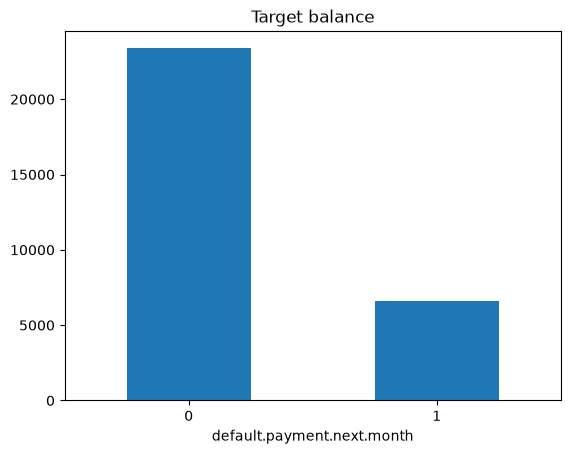

In [2]:
df[TARGET].value_counts().plot.bar(title="Target balance", rot=0)
plt.show()

## Категориальные признаки

`EDUCATION` содержит недокументированные коды 0, 5, 6 (345 строк), `MARRIAGE` код 0 (54 строки). В `make_dataset.py` они сворачиваются в 4 и 3.

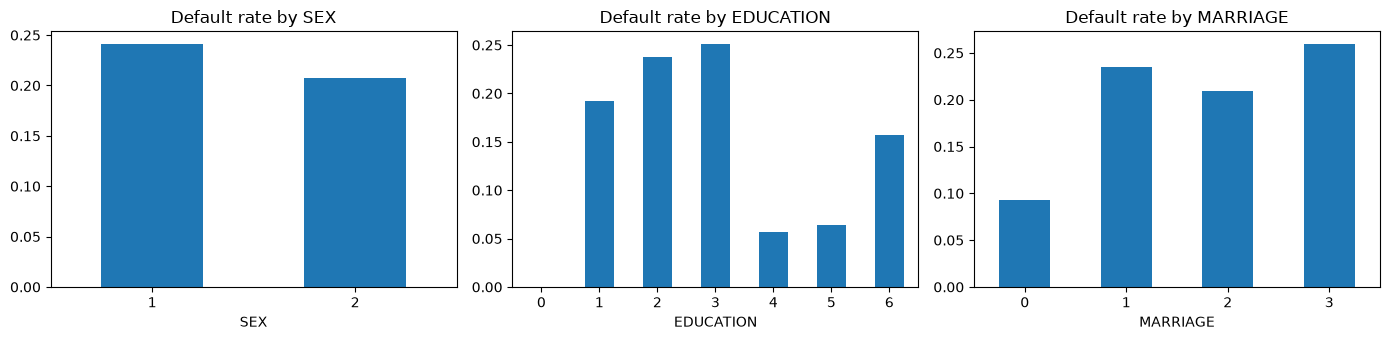

EDUCATION    {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5...
MARRIAGE                   {0: 54, 1: 13659, 2: 15964, 3: 323}
dtype: object

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    df.groupby(col)[TARGET].mean().plot.bar(ax=ax, title=f"Default rate by {col}", rot=0)
plt.tight_layout()
plt.show()
df[["EDUCATION", "MARRIAGE"]].apply(lambda s: s.value_counts().sort_index().to_dict())

## История платежей

Коды `PAY_*`: -2 и -1 без просрочки, 0 револьверный кредит, 1 и выше месяцы просрочки. Доля дефолтов растёт с просрочкой.

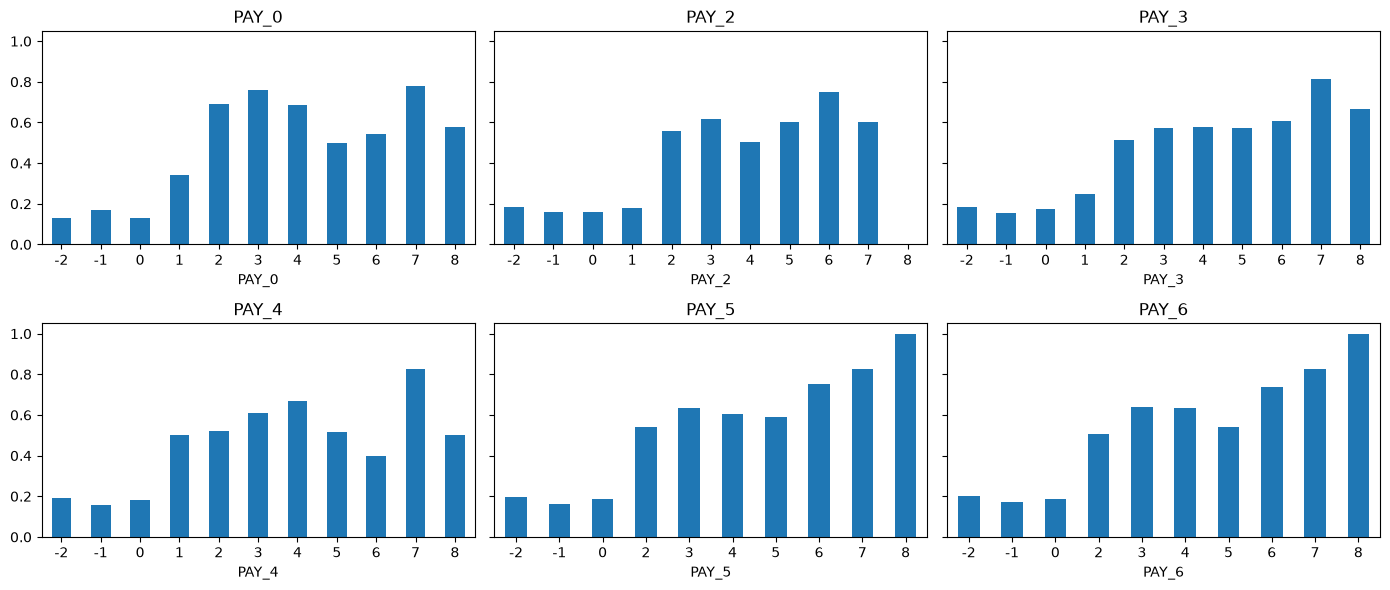

In [4]:
pay = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
for ax, col in zip(axes.ravel(), pay):
    df.groupby(col)[TARGET].mean().plot.bar(ax=ax, title=col, rot=0)
plt.tight_layout()
plt.show()

## Лимит, возраст, счета и платежи

Счета бывают отрицательными (переплата), у сумм платежей и счетов тяжёлый правый хвост, поэтому гистограммы в логарифмической шкале.

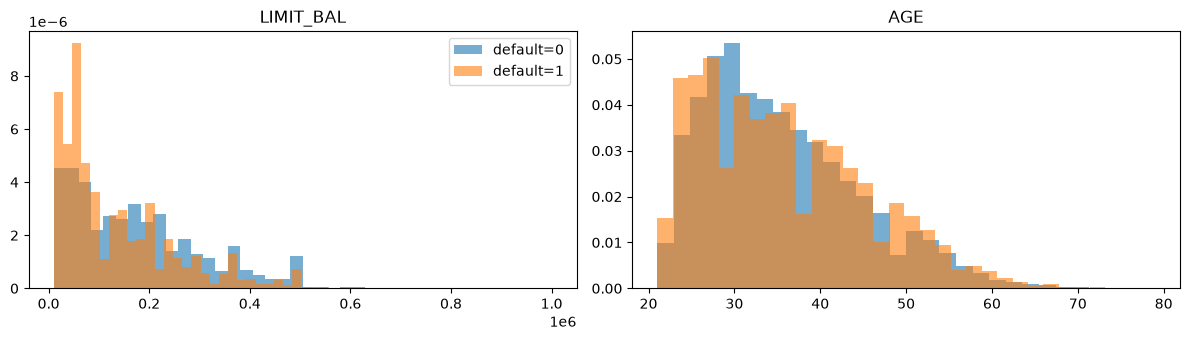

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for label, part in df.groupby(TARGET):
    axes[0].hist(part["LIMIT_BAL"], bins=40, alpha=0.6, density=True, label=f"default={label}")
    axes[1].hist(part["AGE"], bins=30, alpha=0.6, density=True, label=f"default={label}")
axes[0].set_title("LIMIT_BAL")
axes[1].set_title("AGE")
axes[0].legend()
plt.tight_layout()
plt.show()

rows with a negative bill: 1930


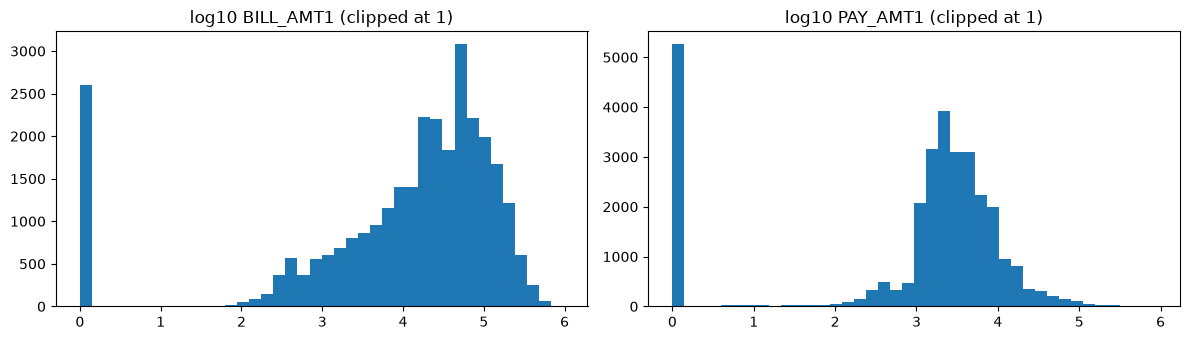

In [6]:
bill = [f"BILL_AMT{i}" for i in range(1, 7)]
payamt = [f"PAY_AMT{i}" for i in range(1, 7)]
print("rows with a negative bill:", int((df[bill] < 0).any(axis=1).sum()))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(np.log10(df["BILL_AMT1"].clip(lower=1)), bins=40)
axes[0].set_title("log10 BILL_AMT1 (clipped at 1)")
axes[1].hist(np.log10(df["PAY_AMT1"].clip(lower=1)), bins=40)
axes[1].set_title("log10 PAY_AMT1 (clipped at 1)")
plt.tight_layout()
plt.show()

## Признаки

Сравнение одномерного ROC-AUC инженерных признаков. Значение ниже 0.5 означает обратную связь с дефолтом. Одномерный AUC не показывает вклад признака в связке с остальными, окончательный отбор по кросс-валидации в `train.py`.

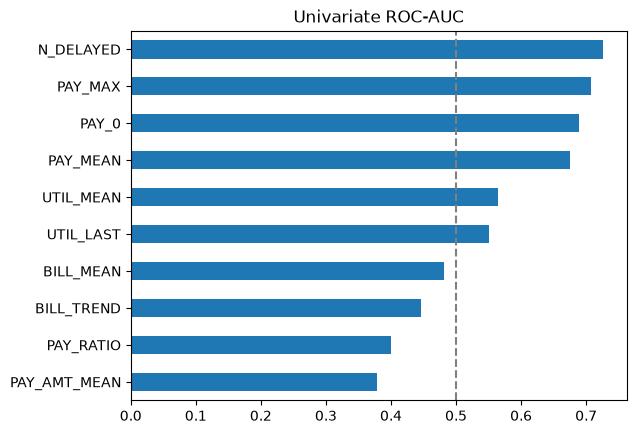

In [7]:
feats = add_features(df)
auc = pd.Series({c: roc_auc_score(df[TARGET], feats[c]) for c in ["PAY_0"] + ENGINEERED_NUMERIC})
auc.sort_values().plot.barh(title="Univariate ROC-AUC")
plt.axvline(0.5, color="grey", linestyle="--")
plt.show()

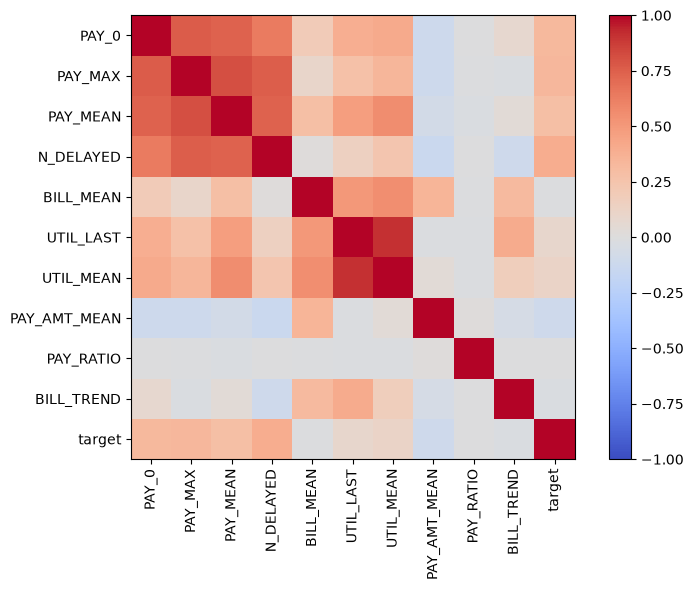

In [8]:
corr = feats[["PAY_0"] + ENGINEERED_NUMERIC].assign(target=df[TARGET]).corr()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im)
plt.tight_layout()
plt.show()

## Что из этого следует для пайплайна

- Очистка: недокументированные коды `EDUCATION` и `MARRIAGE` сворачиваются, `ID` удаляется, строки не удаляются.
- Модель: сильнейший сигнал даёт история просрочек, агрегаты (`N_DELAYED`, `PAY_MAX`) не хуже сырых `PAY_*`.
- Метрики: классы несбалансированы, порог классификации подбирается отдельно от 0.5.